In [118]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from IPython.display import display

### **METODE RELAKSASI / SOR**

**GAUSS-SEIDEL:**

$$
\begin{aligned}
x_i^{(k+1)} &= \frac{1}{a_{ii}} \Bigg(
b_i
- \sum_{j<i} a_{ij} \, x_j^{(k+1)}
- \sum_{j>i} a_{ij} \, x_j^{(k)}
\Bigg)
\end{aligned}
$$

**RELAKSASI/SOR:**
$$
x_i^{(k+1)} = (1 - \omega)\, x_i^{(k)} + \frac{\omega}{a_{ii}} \left(
b_i
- \sum_{j<i} a_{ij} \, x_j^{(k+1)}
- \sum_{j>i} a_{ij} \, x_j^{(k)}
\right)
$$


In [ ]:
def SOR(A, b, omega, epsilon=0.1, max_iter=100):
    n = len(A)
    x = np.zeros(n) #Tebakan awal 0
    history = [x.copy()]
    iterasi = 1

    while iterasi <= max_iter:
        x_old = x.copy()
        
        for i in range(n):
            jumlah = 0
            for j in range(n):
                if j < i:
                    jumlah += A[i][j] * x[j]    
                elif j > i:
                    jumlah += A[i][j] * x_old[j] 
            
            x_gs = (b[i] - jumlah) / A[i][i]
            x[i] = (1 - omega) * x_old[i] + omega * x_gs

        history.append(x.copy())

        err = max(abs(x[i] - x_old[i]) for i in range(n))
        if err < epsilon:
            return x, history, iterasi

        iterasi += 1

    print("MENCAPAI BATAS ITERASI - 100")
    return x, history, iterasi+1 


### **METODE BiCONJUGASI GRADIEN STABIZLIZED**

In [ ]:
def bicgstab(A, b, epsilon=0.1, max_iter=100):
    # Konversi ke numpy array (biar operasi linear algebra bisa dipakai)
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)

    # Inisialisasi solusi awal (x0 = 0)
    x = np.zeros(n)
    
    # Menyimpan riwayat solusi untuk keperluan grafik
    history = [x.copy()]
    
    # Residual awal: r0 = b - A x0
    r = b - A @ x
    
    # r_hat adalah "vektor bayangan"
    # biasanya diambil sama dengan residual awal
    r_hat = r.copy()
    
    # Inisialisasi parameter BiCGSTAB
    rho_prev = 1.0   # skalar untuk update arah
    alpha = 1.0      # langkah utama (mirip CG)
    omega = 1.0      # langkah stabilisasi
    
    v = np.zeros(n)  # vektor bantu
    p = np.zeros(n)  # arah pencarian (search direction)

    # Loop iterasi utama
    for iterasi in range(max_iter):
        
        # 1. Hitung rho (inner product)
        rho = np.dot(r_hat, r)
        
        # Jika rho = 0 → metode gagal (vektor ortogonal)
        if rho == 0:
            print("Gagal: rho = 0 (breakdown)")
            break
        
        #NOTE MEOTDE (CG)
        # 2. Update arah pencarian p
        beta = (rho / rho_prev) * (alpha / omega)
        
        # Kombinasi arah sebelumnya + koreksi
        p = r + beta * (p - omega * v)
        
        # 3. Hitung v = A p
        v = A @ p
        
        denom = np.dot(r_hat, v)
        if denom == 0:
            print("Gagal: pembagian nol pada alpha")
            break
        
        # 4. Langkah agresif (CG)
        alpha = rho / denom
        
        # Residual sementara
        s = r - alpha * v
    
        #NOTE 5. Langkah stabilisasi
        t = A @ s
        
        t_dot_t = np.dot(t, t)
        
        if t_dot_t == 0:
            print("Gagal: t_dot_t = 0")
            break
        
        # Hitung omega untuk "menstabilkan"
        omega = np.dot(t, s) / t_dot_t
        
        # 6. Update solusi x
        # Gabungan:
        # - langkah agresif (alpha * p)
        # - langkah stabilisasi (omega * s)
        x = x + alpha * p + omega * s
        
        # 7. Update residual baru 
        r = s - omega * t
        
        # Simpan riwayat solusi
        history.append(x.copy())
        
        # 8. Cek konvergensi
        # Menggunakan residual
        error = np.linalg.norm(r) / np.linalg.norm(b)
        
        if error < epsilon:
            return x, history, iterasi + 1
        
        # Simpan rho untuk iterasi berikutnya
        rho_prev = rho

    print("Mencapai batas iterasi maksimum")
    return x, history, len(history)


### **OUTPUT + GRAFIK**

In [121]:
def output_sor(kasus, omega):
    A, b = kasus
    tabel_data = []


    solusi, history, iterasi = SOR(A, b, omega)
        
    # Looping setiap iterasi pada nilai Omega tersebut
    for i in range(len(history)):
        x1_val = history[i][0]
        x2_val = history[i][1]
        x3_val = history[i][2]
        
        # Hitung error (iterasi ke-0 belum punya error)
        if i == 0:
            error_x1 = history[i][i]
            error_x2 = history[i][i]
            error_x3 = history[i][i]
        else:
            # [[a , b] ,[c , d]] --> c - a , d - b 
            error_x1 = abs(history[i][0] - history[i-1][0]) 
            error_x2 =  abs(history[i][1] - history[i-1][1])
            error_x3 =  abs(history[i][2] - history[i-1][2])
            
        # Memasukkan baris data ke dalam list
        tabel_data.append({
            "Omega": omega,
            "Iterasi": i,
            "x1": x1_val,
            "x2": x2_val,
            "x3": x3_val,
            "Error x1": error_x1,
            "Error x2": error_x2,
            "Error x3": error_x3
        })

    # Mengubah list data menjadi tabel Pandas DataFrame
    df = pd.DataFrame(tabel_data)
    
    # Menampilkan tabel dengan rapi di Jupyter Notebook
    display(df)

In [122]:
def output_bicgstab(kasus):
    A, b = kasus
    tabel_data = []

    solusi, history, iterasi = bicgstab(A, b)
        
    # Looping setiap iterasi pada nilai Omega tersebut
    for i in range(len(history)):
        x1_val = history[i][0]
        x2_val = history[i][1]
        x3_val = history[i][2]
        
        # Hitung error (iterasi ke-0 belum punya error)
        if i == 0:
            error_x1 = history[i][i]
            error_x2 = history[i][i]
            error_x3 = history[i][i]
        else:
        # [[a , b] ,[c , d]] --> c - a , d - b 
            error_x1 = abs(history[i][0] - history[i-1][0]) 
            error_x2 =  abs(history[i][1] - history[i-1][1])
            error_x3 =  abs(history[i][2] - history[i-1][2])
            
        # Memasukkan baris data ke dalam list
        tabel_data.append({
            "Metode": "BiConjugate Gradient Stabilized",
            "Iterasi": i,
            "x1": x1_val,
            "x2": x2_val,
            "x3": x3_val,
            "Error x1": error_x1,
            "Error x2": error_x2,
            "Error x3": error_x3,
        })

    # Mengubah list data menjadi tabel Pandas DataFrame
    df = pd.DataFrame(tabel_data)
    
    # Menampilkan tabel dengan rapi di Jupyter Notebook
    display(df)

# **KASUS**

# 📌 Kasus Alokasi Cache Memory pada Prosesor Modern

Kasus ini memodelkan permasalahan **alokasi cache memory** pada prosesor modern yang terdiri dari tiga level cache:

- **L1 Cache**
- **L2 Cache**
- **L3 Cache**

Ketiga cache ini harus dialokasikan secara optimal untuk melayani tiga jenis proses yang berjalan bersamaan.

---

## 🔹 Karakteristik Proses

### 🧠 Process A (CPU-intensive)
- Dominan mengakses cache **L1**
- Sedikit akses ke L2 dan L3

### 💾 Process B (Memory-intensive)
- Dominan mengakses cache **L2**
- Sedikit akses ke L1 dan L3

### 🔌 Process C (I/O-intensive)
- Dominan mengakses cache **L3**
- Sedikit akses ke L1 dan L2

---

## 🔹 Pemodelan Sistem Persamaan Linear (SPL)

Misalkan:

- $x$ = kapasitas cache **L1** (MB)
- $y$ = kapasitas cache **L2** (MB)
- $z$ = kapasitas cache **L3** (MB)

Maka diperoleh sistem persamaan:

$$
\begin{cases}
9x + 2y + z = 55 \\
x + 7y + 2z = 41 \\
2x + y + 8z = 37
\end{cases}
$$

---

## 🔹 Interpretasi Matriks

Sistem di atas dapat ditulis dalam bentuk matriks:

$$
\begin{bmatrix}
9 & 2 & 1 \\
1 & 7 & 2 \\
2 & 1 & 8
\end{bmatrix}
\begin{bmatrix}
x \\
y \\
z
\end{bmatrix}
=
\begin{bmatrix}
55 \\
41 \\
37
\end{bmatrix}
$$

---

## 🔹 Representasi Matriks

$$
A =
\begin{bmatrix}
9 & 2 & 1 \\
1 & 7 & 2 \\
2 & 1 & 8
\end{bmatrix}
\quad
b =
\begin{bmatrix}
55 \\
41 \\
37
\end{bmatrix}
$$

---

## 🔹 Tujuan

Menentukan nilai optimal:

- $x$ → alokasi cache L1  
- $y$ → alokasi cache L2  
- $z$ → alokasi cache L3  

agar performa sistem prosesor menjadi optimal untuk ketiga jenis proses.

---

In [123]:
#Kasus 2
A = np.array([
    [9, 2, 1],
    [1, 7, 2],
    [2, 1, 8]
], dtype= float)

b = np.array([
    55,
    41,
    37
], dtype= float)

kasus2 = (A, b)

## **TABEL SOR**

In [124]:
# Tabel
omega_list = [0.5 ,1.0, 1.5]
for o in omega_list:
    output_sor(kasus2, o)

,Omega,Iterasi,x1,x2,x3,Error x1,Error x2,Error x3
0,0.5,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.5,1,3.055556,2.710317,1.761161,3.055556,2.710317,1.761161
2,0.5,2,4.184345,3.733254,2.436709,1.128789,1.022937,0.675548
3,0.5,3,4.597549,4.118701,2.698742,0.413204,0.385447,0.262033
4,0.5,4,4.746767,4.263332,2.802067,0.149217,0.144632,0.103325
5,0.5,5,4.799565,4.317116,2.843768,0.052798,0.053784,0.041701


,Omega,Iterasi,x1,x2,x3,Error x1,Error x2,Error x3
0,1.0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1.0,1,6.111111,4.984127,2.474206,6.111111,4.984127,2.474206
2,1.0,2,4.728616,4.474710,2.883507,1.382496,0.509417,0.409301
3,1.0,3,4.796341,4.348092,2.882403,0.067726,0.126618,0.001104
4,1.0,4,4.824601,4.344370,2.875803,0.028260,0.003722,0.006600


,Omega,Iterasi,x1,x2,x3,Error x1,Error x2,Error x3
0,1.5,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1.5,1,9.166667,6.821429,2.220982,9.166667,6.821429,2.220982
2,1.5,2,1.939360,4.007573,4.348329,7.227307,2.813855,2.127347
3,1.5,3,6.136407,3.603414,1.786543,4.197047,0.404160,2.561786
4,1.5,4,4.599568,5.232725,3.338255,1.536839,1.629311,1.551712
5,1.5,5,4.566265,3.760186,2.850988,0.033303,1.472539,0.487267
6,1.5,6,5.154974,4.579132,2.720303,0.588709,0.818946,0.130685
7,1.5,7,4.609418,4.342571,3.034584,0.545555,0.236560,0.314281
8,1.5,8,4.908670,4.262035,2.780325,0.299251,0.080537,0.254259
9,1.5,9,4.828266,4.428501,2.906394,0.080403,0.166466,0.126068


## **GRAFIK SOR**

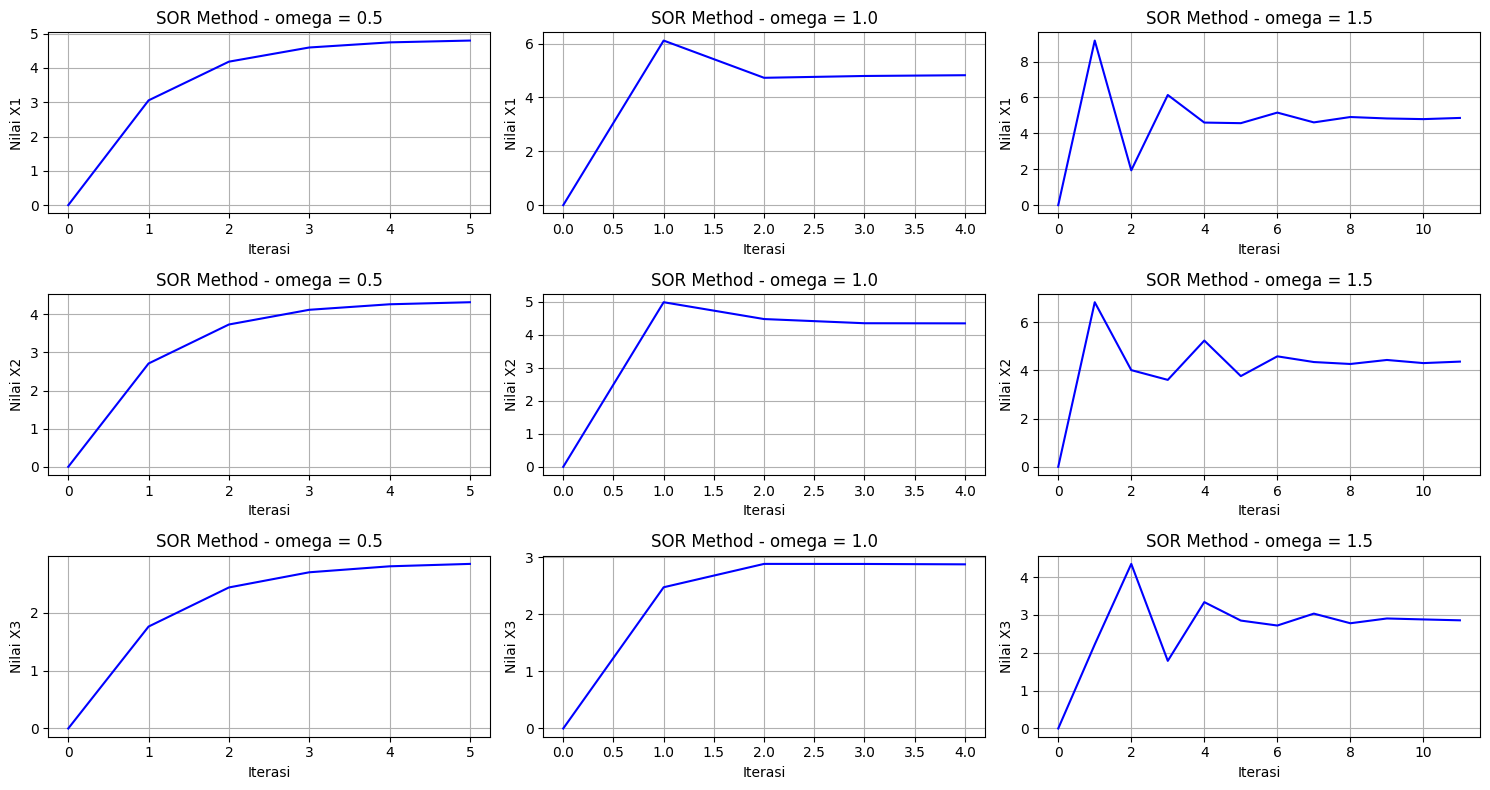

In [125]:
# Grafik
omega_list = [0.5 ,1.0, 1.5]

#Membuat template 3 baris 3 kolom
fig, axs = plt.subplots (len(A), len(omega_list), figsize = (15, 8))

for n in range(len(omega_list)):
    x, history, iterasi = SOR(A, b, omega_list[n])
    
    for baris in range(len(A)):
        #Kolom n
        axs[baris][n].plot(range(len(history)), #sumbu x
                    [h[baris] for h in history], #sumbu y
                    color='blue')
        axs[baris][n].set_title(f'SOR Method - omega = {omega_list[n]}')
        axs[baris][n].set_xlabel('Iterasi')
        axs[baris][n].set_ylabel(f'Nilai X{baris+1}')
        axs[baris][n].grid(True)
        
        # Agar antar grafik tidak saling bertabrakan (merapikan tata letak)
plt.tight_layout()

        # Tampilkan
plt.show()

## **TABEL BiCGSTAB**

In [126]:
# Tabel
x, history, iterasi = bicgstab(A, b)
output_bicgstab(kasus2)

,Metode,Iterasi,x1,x2,x3,Error x1,Error x2,Error x3
0,BiConjugate Gradient Stabilized,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,BiConjugate Gradient Stabilized,1,4.900401,4.256874,2.805184,4.900401,4.256874,2.805184
2,BiConjugate Gradient Stabilized,2,4.825704,4.346139,2.876301,0.074697,0.089264,0.071117
3,BiConjugate Gradient Stabilized,3,4.825806,4.346237,2.875269,0.000103,0.000098,0.001032


## **GRAFIK BiCGSTAB**

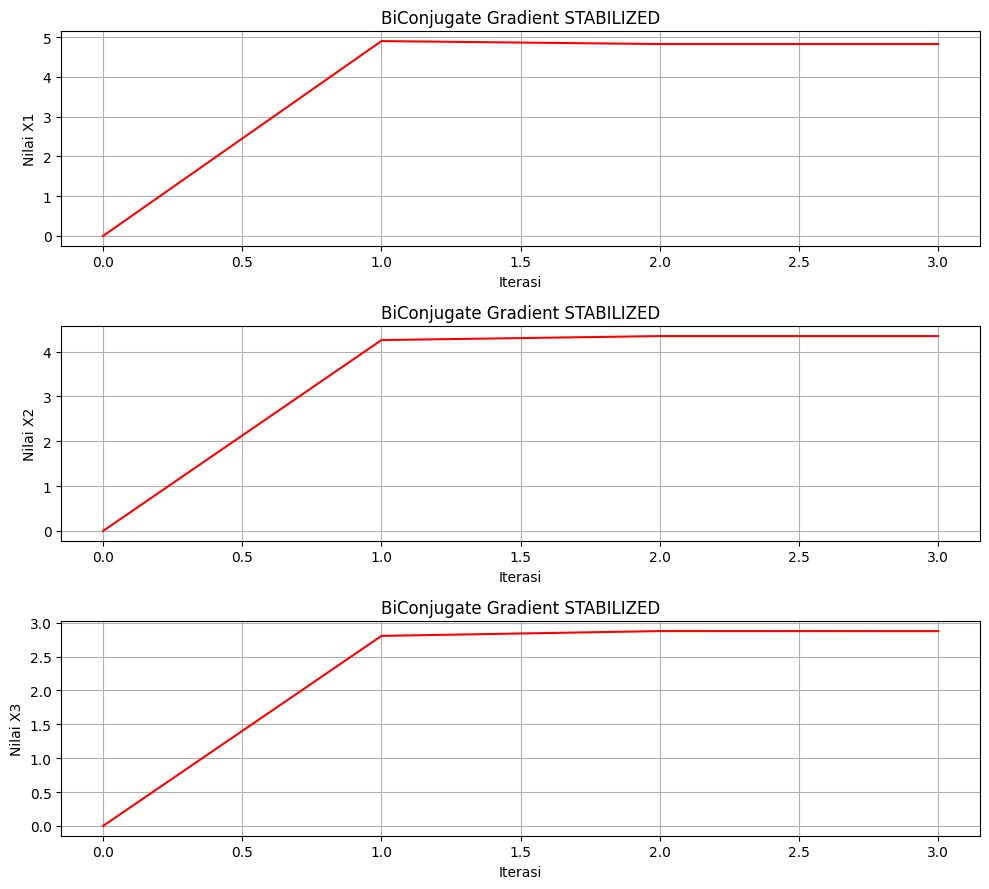

In [127]:
# Grafik

#Membuat template 2 baris 1
fig, axs = plt.subplots (len(A), 1, figsize = (10, 9))


x, history, iterasi = bicgstab(A, b)
    
for baris in range(len(A)):
    #Kolom n
    axs[baris].plot(range(len(history)), #sumbu x
                [h[baris] for h in history], #sumbu y
                color='red')
    axs[baris].set_title(f'BiConjugate Gradient STABILIZED')
    axs[baris].set_xlabel('Iterasi')
    axs[baris].set_ylabel(f'Nilai X{baris+1}')
    axs[baris].grid(True)
    
    # Agar antar grafik tidak saling bertabrakan (merapikan tata letak)
plt.tight_layout()

        # Tampilkan
plt.show()

## **GRAFIK PERBANDINGAN**

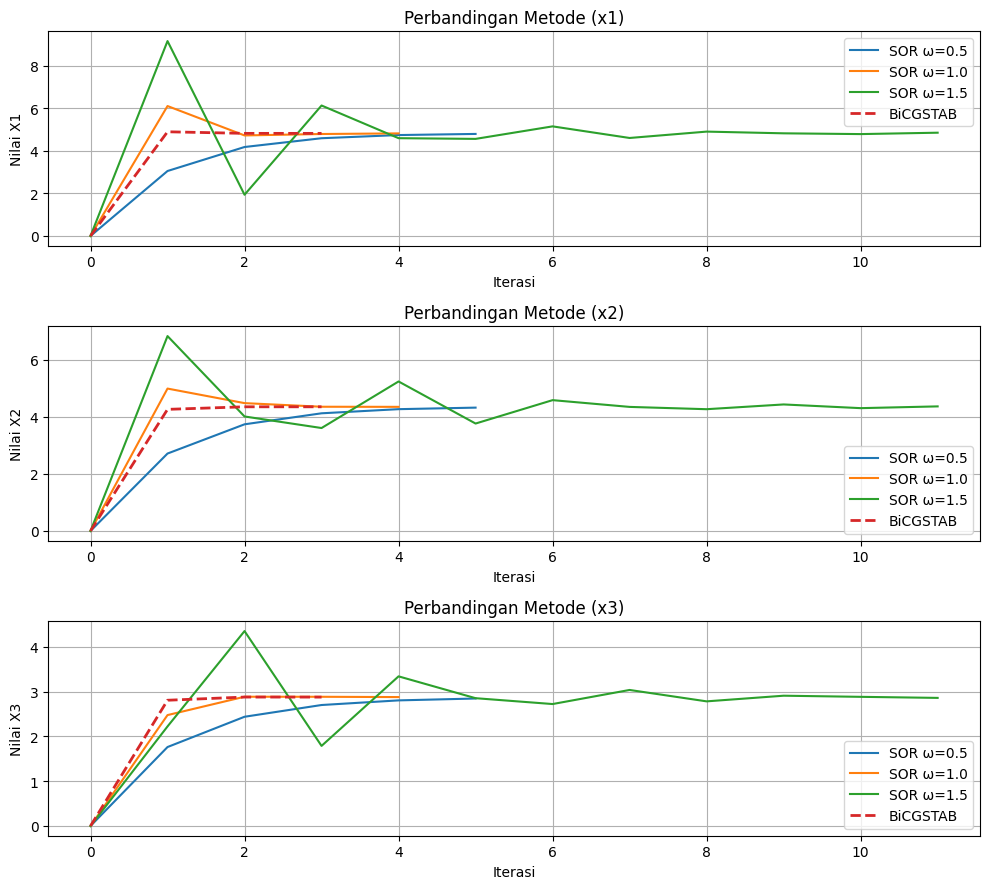

In [128]:
omega_list = [0.5, 1.0, 1.5]

fig, axs = plt.subplots(len(A), 1, figsize=(10, 9))


# Plot SOR dulu

for n in range(len(omega_list)):
    x_sor, history_sor, _ = SOR(A, b, omega_list[n])
    
    for baris in range(len(A)):
        axs[baris].plot(
            range(len(history_sor)),
            [h[baris] for h in history_sor],
            label=f'SOR ω={omega_list[n]}'
        )


# Plot BiCGSTAB

x_bicg, history_bicg, _ = bicgstab(A, b)

for baris in range(len(A)):
    axs[baris].plot(
        range(len(history_bicg)),
        [h[baris] for h in history_bicg],
        linestyle='--',  # beda style biar kelihatan
        linewidth=2,
        label='BiCGSTAB'
    )


# Styling

for baris in range(len(A)):
    axs[baris].set_title(f'Perbandingan Metode (x{baris+1})')
    axs[baris].set_xlabel('Iterasi')
    axs[baris].set_ylabel(f'Nilai X{baris+1}')
    axs[baris].grid(True)
    axs[baris].legend()   # 

plt.tight_layout()
